# Wykonywanie zlozonych operacji matematycznych w SageMath

In [1]:
# x = var('x')
y = var('y')
z, phi = var('z, phi')
eq = z**2 - 2/cos(phi)*z + 5/cos(phi)**2 - 4 == 0;
show(eq.lhs())

z^2 - 2*z/cos(phi) + 5/cos(phi)^2 - 4

In [2]:
show( solve(eq, z) )

[z == -(2*sqrt(cos(phi)^2 - 1) - 1)/cos(phi), z == (2*sqrt(cos(phi)^2 - 1) + 1)/cos(phi)]

In [3]:
show( solve([x+y == 3, 2*x+2*y == 6], x, y) )

[[x == -r1 + 3, y == r1]]

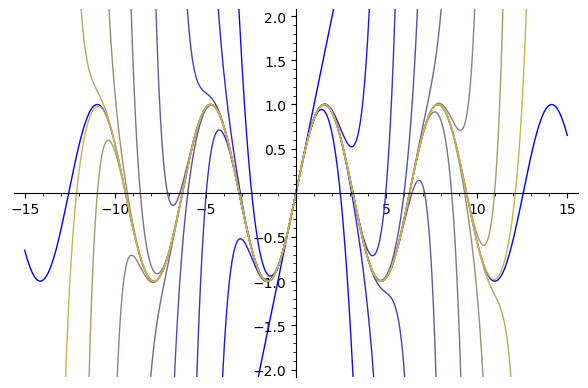

In [4]:
def p(x, n):
    return(taylor(sin(x), x, 0, n))
xmax = 15 ; n = 15
g = plot(sin(x), x, -xmax, xmax)
for d in range(n):
    g += plot(p(x, 2 * d + 1), x, -xmax, xmax,\
    color=(1.7*d/(2*n), 1.5*d/(2*n), 1-3*d/(4*n)))
g.show(ymin=-2, ymax=2)

Animation with 14 frames
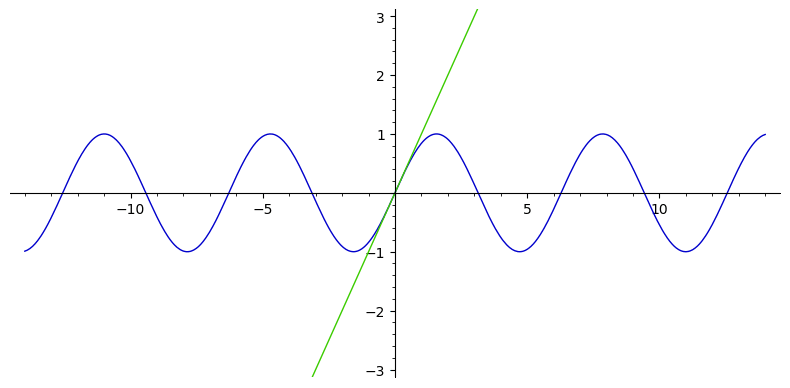

In [5]:
a = animate([[sin(x), taylor(sin(x), x, 0, 2*k+1)]\
for k in range(0, 14)], xmin=-14, xmax=14,\
ymin=-3, ymax=3, figsize=[8, 4])
a.show()

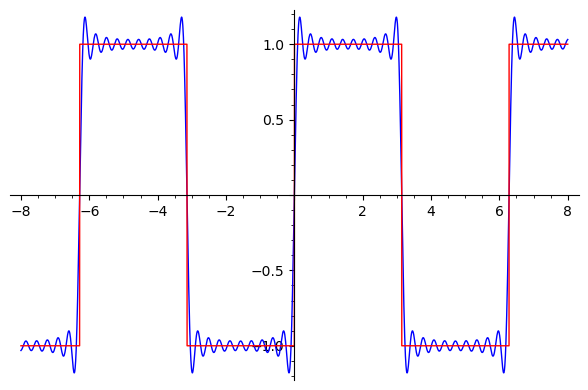

In [6]:
f2(x) = 1; f1(x) = -1
f = piecewise([[(-pi,0),f1],[(0,pi),f2]])
S = f.fourier_series_partial_sum(20,pi)
g = plot(S, x, -8, 8, color='blue')
saw(x) = x - 2 * pi * floor((x + pi) / (2 * pi))
g += plot(saw(x) / abs(saw(x)), x, -8, 8, color='red')
g

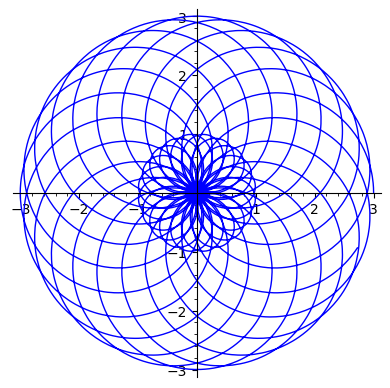

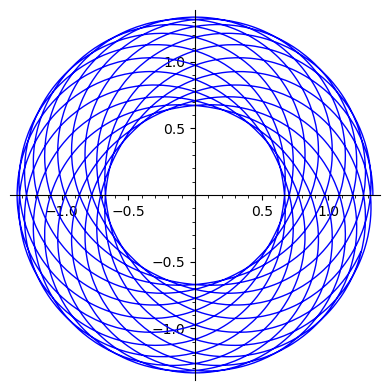

In [7]:
t = var('t'); n = 20/19
g1 = polar_plot(1+2*cos(n*t),(t,0,n*36*pi),plot_points=5000)
g2 = polar_plot(1+1/3*cos(n*t),(t,0,n*36*pi),plot_points=5000)
g1.show(aspect_ratio=1); g2.show(aspect_ratio=1)

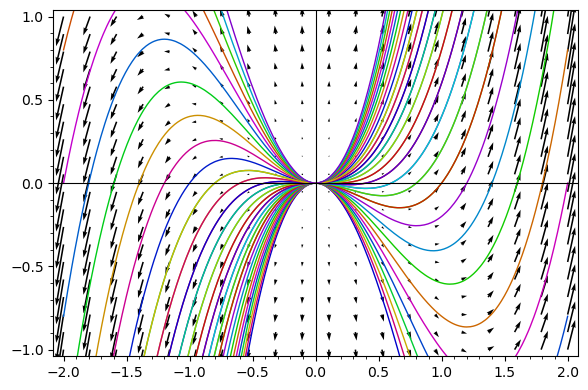

In [8]:
x = var('x'); y = function('y')
DE = x*diff(y(x), x) == 2*y(x) + x^3
desolve(DE, [y(x),x])
sol = []
for i in srange(-2, 2, 0.2):
	sol.append(desolve(DE, [y(x), x], ics=[1, i]))
	sol.append(desolve(DE, [y(x), x], ics=[-1, i]))
g = plot(sol, x, -2, 2)
y = var('y')
g += plot_vector_field((x, 2*y+x^3), (x,-2,2), (y,-1,1))
g.show(ymin=-1, ymax=1)

In [9]:
x, y, t = var('x, y, t')
alpha(t) = 1; beta(t) = t / 2; gamma(t) = t + t^3 / 8
env = solve([alpha(t) * x + beta(t) * y == gamma(t),\
diff(alpha(t), t) * x + diff(beta(t), t) * y == \
diff(gamma(t), t)], [x,y])
show(env)

[[x == -1/4*t^3, y == 3/4*t^2 + 2]]

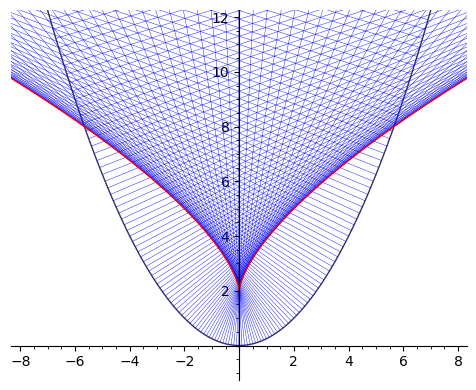

In [10]:
f(x) = x^2 / 4
p = plot(f, -8, 8, rgbcolor=(0.2,0.2,0.4)) # the parabola
for u in srange(0, 8, 0.1): # normals to the parabola
    p += line([[u, f(u)], [-8*u, f(u) + 18]], thickness=.3)
    p += line([[-u, f(u)], [8*u, f(u) + 18]], thickness=.3)
p += parametric_plot((env[0][0].rhs(),env[0][1].rhs()),\
(t, -8, 8),color='red') # draws the evolute
p.show(xmin=-8, xmax=8, ymin=-1, ymax=12, aspect_ratio=1)

In [11]:
u = function('u')(x)
y = x*u
DE = x*diff(y,x) == y + sqrt(x**2 + y**2)
show(DE)

(x*diff(u(x), x) + u(x))*x == x*u(x) + sqrt(x^2*u(x)^2 + x^2)

In [12]:
assume(x>0)
sol=desolve(DE, u)
show(sol)

x == _C*e^arcsinh(u(x))

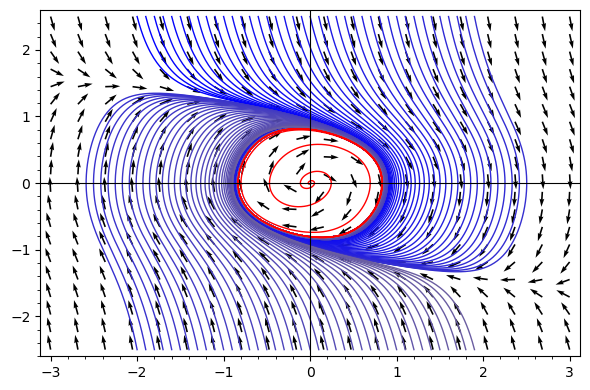

In [13]:
from scipy import integrate
def dX_dt(X, t=0): return [X[1], 0.5*X[1] - X[0] - X[1]^3]
t = srange(0, 40, 0.01); x0 = srange(-2, 2, 0.1); y0 = 2.5
CI = [[i, y0] for i in x0] + [[i, -y0] for i in x0]
def g(x,y): v = vector(dX_dt([x, y])); return v / v.norm()
x, y = var('x, y'); n = len(CI)
q = plot_vector_field(g(x, y), (x, -3, 3), (y, -y0, y0))
for j in range(n):
    X = integrate.odeint(dX_dt, CI[j], t)
    q += line(X, color=(1.7*j/(4*n),1.5*j/(4*n),1-3*j/(8*n)))
X = integrate.odeint(dX_dt, [0.01,0], t)
q += line(X, color = 'red'); q.show()